In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [41]:
import warnings
warnings.filterwarnings("ignore")

# loading the dataset

In [42]:
sam=pd.read_csv(r"C:\Users\krish\Downloads\spam1.csv",encoding='cp1252')

In [43]:
sam

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN
...,...,...,...,...,...
6771,spam,This is the 2nd time we have tried 2 contact u...,NaN,NaN,NaN
6772,ham,Will Ì_ b going to esplanade fr home?,NaN,NaN,NaN
6773,ham,"Pity, * was in mood for that. So...any other s...",NaN,NaN,NaN
6774,ham,The guy did some bitching but I acted like i'd...,NaN,NaN,NaN


In [44]:
sam.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [45]:
sam.shape

(6776, 5)

In [46]:
sam.columns

Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='object')

In [47]:
sam.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6776 entries, 0 to 6775
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          6776 non-null   object
 1   v2          6776 non-null   object
 2   Unnamed: 2  56 non-null     object
 3   Unnamed: 3  16 non-null     object
 4   Unnamed: 4  8 non-null      object
dtypes: object(5)
memory usage: 264.8+ KB


# clean and prepare dataset

In [48]:
# clean and prepare dataset
sam=sam.dropna(subset=['v1']).copy()

In [49]:
#combine the message columns and any extra text columns 
text_columns=['v2']+[col for col in sam.columns
                    if col.startswith('Unnamed:')]

In [50]:
sam['message']=(
    sam[text_columns]
    .fillna("")
    .astype(str)
    .agg("".join,axis=1)
    .str.strip()
)

In [51]:
#keep only valid labels and non-empty messeges
sam=sam[sam['v1'].isin(["ham","spam"])]
sam=sam[sam['message']!=""]

In [52]:
#rename target column 
sam=sam.rename(columns={'v1':'label'})

In [53]:
#keep only required columns
sam=sam[['label','message']].drop_duplicates()

In [54]:
sam.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [55]:
sam.shape

(5154, 2)

In [56]:
sam.label.value_counts()

label
ham     4513
spam     641
Name: count, dtype: int64

In [57]:
sam.isnull().sum()

label      0
message    0
dtype: int64

# EDA 

In [58]:
sam.label.value_counts()

label
ham     4513
spam     641
Name: count, dtype: int64

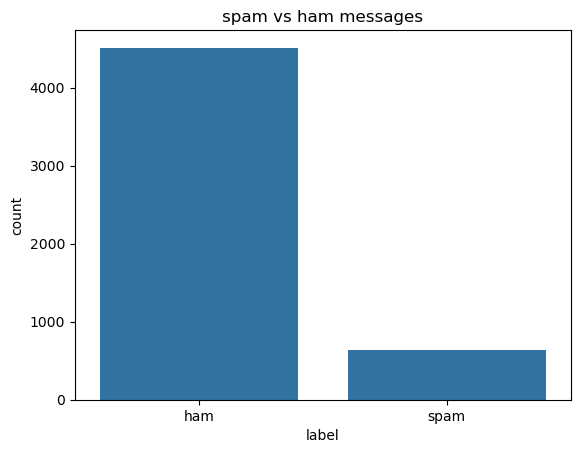

In [59]:
#visual the counts
sns.countplot(data=sam,x='label')
plt.title('spam vs ham messages')
plt.show()

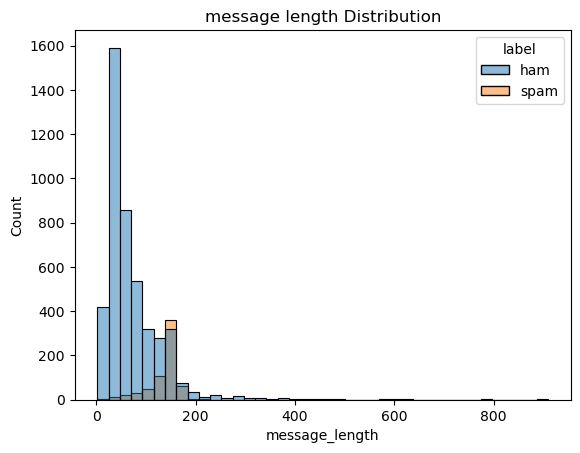

In [60]:
#check the message length
sam['message_length']=sam['message'].str.len()
sns.histplot(
    data=sam,
    x="message_length",
    hue='label',
    bins=40
)
plt.title('message length Distribution')
plt.show()

# text preprocessing

In [61]:
x=sam['message']
y=sam['label']
x.head()
y.value_counts()

label
ham     4513
spam     641
Name: count, dtype: int64

In [62]:
x.head()

0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: message, dtype: object

In [63]:
y.head()

0     ham
1     ham
2    spam
3     ham
4     ham
Name: label, dtype: object

# split data into training and testing

In [64]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=0.2,random_state=42,
    stratify=y
)


In [65]:
print("Training data:", len(x_train))
print("Testing data:", len(x_test))
print("Training labels:", len(y_train))
print("Testing labels:", len(y_test))

Training data: 4123
Testing data: 1031
Training labels: 4123
Testing labels: 1031


In [66]:
x=sam['message']
y=sam['label']

# nlp model

In [67]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2)
    )),
    ("classifier", MultinomialNB())
])

model.fit(x_train, y_train)

print("Model training completed!")

Model training completed!


# Evaluation the model

In [68]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(x_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Accuracy: 0.9582929194956353

Classification Report:

              precision    recall  f1-score   support

         ham       0.95      1.00      0.98       903
        spam       1.00      0.66      0.80       128

    accuracy                           0.96      1031
   macro avg       0.98      0.83      0.89      1031
weighted avg       0.96      0.96      0.95      1031



# visualize the confusion matrix

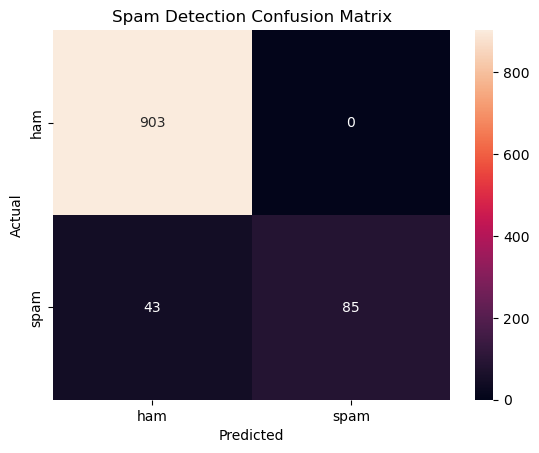

In [69]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["ham", "spam"]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["ham", "spam"],
    yticklabels=["ham", "spam"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Spam Detection Confusion Matrix")
plt.show()

# testing the model


In [70]:
message = ["Congratulations! You have won a free prize. Call now!"]

prediction = model.predict(message)[0]

if prediction == "spam":
    print("This message is SPAM")
else:
    print("This message is HAM (Normal)")

This message is SPAM


In [71]:
message = ["Hi, are we meeting for lunch today?"]

print("Prediction:", model.predict(message)[0])

Prediction: ham


# compare multiple algorithms

In [72]:
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Naive Bayes": model,
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            ngram_range=(1, 2)
        )),
        ("classifier", LogisticRegression(max_iter=1000))
    ]),
    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            ngram_range=(1, 2)
        )),
        ("classifier", LinearSVC())
    ])
}

results = []

for name, clf in models.items():
    clf.fit(x_train, y_train)
    predictions = clf.predict(x_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Spam F1-score": f1_score(
            y_test, predictions, pos_label="spam"
        )
    })

results_df = pd.DataFrame(results)
print(results_df.sort_values("Spam F1-score", ascending=False))

                 Model  Accuracy  Spam F1-score
2           Linear SVM  0.990301       0.959677
1  Logistic Regression  0.961203       0.814815
0          Naive Bayes  0.958293       0.798122


# saving best model

In [73]:
import joblib

best_model = models["Linear SVM"]

joblib.dump(best_model, "spam_model.pkl")

print("Best model saved successfully!")

Best model saved successfully!


# testing with new message

In [39]:
test_messages = [
    "Congratulations! You have won a free prize. Call now!",
    "Hi, are we meeting for lunch today?"
]

for message in test_messages:
    prediction = best_model.predict([message])[0]
    print("Message:", message)
    print("Prediction:", prediction.upper())
    print()

Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM

Message: Hi, are we meeting for lunch today?
Prediction: HAM



In [74]:
import os 
print(os.path.exists("spam_model.pkl"))

True
